# Weights matrix for Moran's I

In [1]:
from typing import Literal

import geopandas as gpd
import libpysal

from desakota.paths import DataLayout

LEVEL: Literal['DISTRICT', 'COMMUNE'] = 'COMMUNE'  # must match the level 01 last wrote


def load_admin_units(level: Literal['DISTRICT', 'COMMUNE']) -> gpd.GeoDataFrame:
    layout = DataLayout.from_env().ensure()
    return gpd.read_file(layout.processed / f'{level.lower()}s_built_frac.gpkg')  # EPSG:32648


admin_units = load_admin_units(LEVEL)


def build_queen_weights(units: gpd.GeoDataFrame) -> libpysal.weights.W:
    # Queen contiguity (shared edge or vertex), row-standardized
    w_queen = libpysal.weights.Queen.from_dataframe(units, use_index=True)
    w_queen.transform = 'r'
    return w_queen


w_queen = build_queen_weights(admin_units)
len(w_queen.neighbors)

('WARNING: ', 1124, ' is an island (no neighbors)')


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There is 1 island with id: 1124.
  W.__init__(self, neighbors, ids=ids, **kw)


2136

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/spreg/diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'Moran Scatterplot (0.75)'}, xlabel='Attribute', ylabel='Spatial Lag'>)

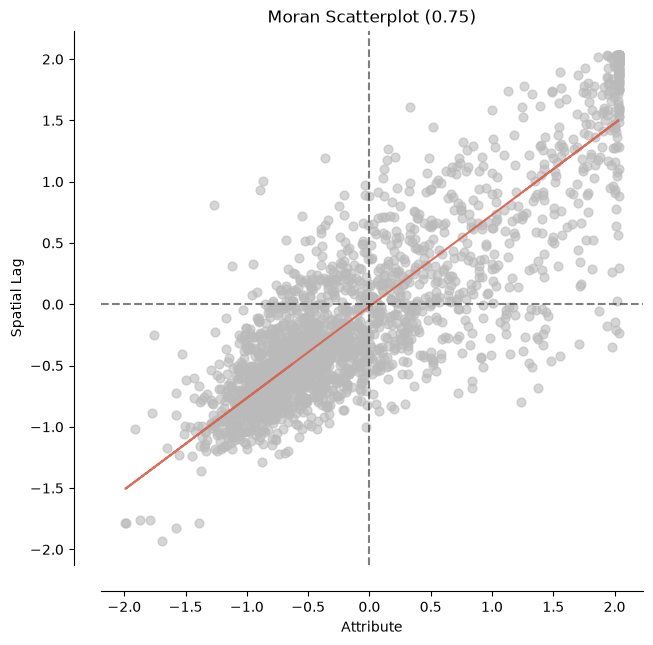

In [2]:
import esda
from splot.esda import lisa_cluster, moran_scatterplot

moran_built_frac = esda.moran.Moran(admin_units['built_frac'], w_queen)

# moran_built_frac.I
# moran_built_frac.p_sim

moran_scatterplot(moran_built_frac)

# Local Moran's I (LISA)

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/esda/moran.py:1398: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


(<Figure size 640x480 with 1 Axes>, <Axes: >)

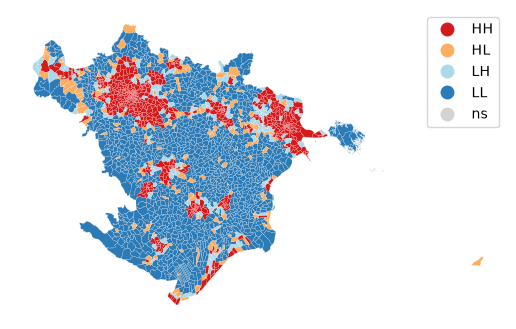

In [3]:
lisa_built_frac = esda.moran.Moran_Local(admin_units['built_frac'], w_queen)

lisa_cluster(lisa_built_frac, admin_units, p=0.5)